# Analisis Data Fasilitas Kesehatan Puskesmas — DKI Jakarta

**Tujuan:** Menganalisis distribusi geografis dan kualitas data fasilitas Puskesmas dari dataset Satu Data Jakarta menggunakan Python di Google Colab. Dari data sederhana berikut menjadi tantangan dalam menjawab pertanyaan sejauh mana data-data jumlah fasilitas kesehatan di wilayah DKI Jakarta menjaid patokan sejauh mana akses masyarakat yang tinggal di jakarta kepada fasilitas kesehatan yang ada di Jakarta.

Hal ini tentunya memunculkan pertanyaan analitis terkait data tersebut :

**Pertanyaan analitis**

1. Bagaimana jumlah catatan Puskesmas tersebar antarwilayah administrasi?
2. Apakah terdapat duplikasi, nilai kosong, atau masalah format pada kolom penting?
3. Bagaimana sebaran lokasi geografis berdasarkan longitude dan latitude?
4. Data tambahan apa yang diperlukan untuk menilai pemerataan akses?

**Catatan penting:** file yang diunggah berekstensi `.xls`, tetapi kontennya berupa tabel HTML. Karena itu, notebook membaca tabel menggunakan `pandas.read_html()`, bukan `pd.read_excel()`. Analisis ini bersifat deskriptif dan tidak menyimpulkan pemerataan akses hanya dari jumlah fasilitas.

## 1. Upload file dan import library

In [1]:
from google.colab import files
uploaded = files.upload()  # Pilih file dataset Puskesmas yang diunduh dari portal

import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

filename = next(iter(uploaded))
print("File:", filename)
print("Ukuran file (bytes):", len(uploaded[filename]))

Saving data-fasilitas-kesehatan-pusat-kesehatan-masyarakat-(puskesmas)-komponen-data.xls to data-fasilitas-kesehatan-pusat-kesehatan-masyarakat-(puskesmas)-komponen-data.xls
File: data-fasilitas-kesehatan-pusat-kesehatan-masyarakat-(puskesmas)-komponen-data.xls
Ukuran file (bytes): 14171


## 2. Baca dan inspeksi data

In [2]:
# File sumber berekstensi .xls, tetapi isi aktualnya adalah tabel HTML
tables = pd.read_html(io.BytesIO(uploaded[filename]))
print("Jumlah tabel ditemukan:", len(tables))

df_raw = tables[0].copy()
print("Ukuran data:", df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes)

Jumlah tabel ditemukan: 1
Ukuran data: (44, 10)


,periode_data,id_puskesmas,nama_puskesmas,wilayah_puskesmas,alamat_puskesmas,no_telepon,email,longitude_puskesmas,latitude_puskesmas,website_puskesmas
0,2025,31710200020,PUSKESMAS CEMPAKA PUTIH,KOTA ADM. JAKARTA PUSAT,JL. PRAMUKA SARI I RT 14 RW 08,021-4219548,PUSKESMASKECCEMPUT@JAKARTA.GO.ID,106.870697,-6.190218,PUSKESMASCEMPAKAPUTIH.JAKARTA.GO.ID
1,2025,31710200032,PUSKESMAS GAMBIR,KOTA ADM. JAKARTA PUSAT,JL. TANAH ABANG I / 10,021-3810051,PUSKESMASGAMBIR@JAKARTA.GO.ID,106.819265,-6.170646,PUSKESMASGAMBIR.JAKARTA.GO.ID
2,2025,31710200014,PUSKESMAS JOHAR BARU,KOTA ADM. JAKARTA PUSAT,JL. MARDANI RAYA NO. 36 RT 02/05,(021) 4256443,PUSKESMAS.JOHARBARU@JAKARTA.GO.ID,106.861804,-6.181068,HTTPS://PUSKESMAS.JOHARBARU.ID/
3,2025,31710200023,PUSKESMAS KEMAYORAN,KOTA ADM. JAKARTA PUSAT,JL. HARAPAN MULIA NO. 1 RT 12/04,(021) 4251018,"PKCKEMAYORAN@GMAIL.COM, PUSKESMASKECKEMAYORAN@...",106.855339,-6.171444,HTTPS://PUSKESMASKEMAYORAN.JAKARTA.GO.ID/
4,2025,31710200006,PUSKESMAS MENTENG,KOTA ADM. JAKARTA PUSAT,JL. PEGANGSAAN BARAT NO. 14 RT 16/05,021-3103439,PKM_KECMENTENG2YAHOO.CO.ID,106.841335,-6.199409,HTTPS://PUSKESMASMENTENG.JAKARTA.GO.ID/


,0
periode_data,int64
id_puskesmas,int64
nama_puskesmas,object
wilayah_puskesmas,object
alamat_puskesmas,object
no_telepon,object
email,object
longitude_puskesmas,float64
latitude_puskesmas,float64
website_puskesmas,object


In [3]:
# Nama kolom, tipe data, dan ringkasan awal
print("Kolom:")
print(df_raw.columns.tolist())

print("\\nInfo dataset:")
df_raw.info()

print("\\nRingkasan nilai unik per kolom:")
display(df_raw.nunique(dropna=False).sort_values(ascending=False).to_frame("jumlah_nilai_unik"))

Kolom:
['periode_data', 'id_puskesmas', 'nama_puskesmas', 'wilayah_puskesmas', 'alamat_puskesmas', 'no_telepon', 'email', 'longitude_puskesmas', 'latitude_puskesmas', 'website_puskesmas']
\nInfo dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44 entries, 0 to 43
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   periode_data         44 non-null     int64  
 1   id_puskesmas         44 non-null     int64  
 2   nama_puskesmas       44 non-null     object 
 3   wilayah_puskesmas    44 non-null     object 
 4   alamat_puskesmas     44 non-null     object 
 5   no_telepon           44 non-null     object 
 6   email                44 non-null     object 
 7   longitude_puskesmas  44 non-null     float64
 8   latitude_puskesmas   44 non-null     float64
 9   website_puskesmas    44 non-null     object 
dtypes: float64(2), int64(2), object(6)
memory usage: 3.6+ KB
\nRingkasan nilai unik per kolo

,jumlah_nilai_unik
id_puskesmas,44
nama_puskesmas,44
latitude_puskesmas,44
alamat_puskesmas,44
no_telepon,44
email,44
website_puskesmas,44
longitude_puskesmas,44
wilayah_puskesmas,6
periode_data,1


## 3. Data quality assessment

In [4]:
# Periksa nilai kosong dan persentasenya
quality = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "unique_values": df_raw.nunique(dropna=False)
}).sort_values("missing_pct", ascending=False)

display(quality)

print("Duplikasi seluruh baris:", df_raw.duplicated().sum())
print("Duplikasi ID:", df_raw["id_puskesmas"].duplicated().sum())
print("Duplikasi nama:", df_raw["nama_puskesmas"].astype("string").str.strip().str.upper().duplicated().sum())

,missing_count,missing_pct,unique_values
periode_data,0,0.0,1
id_puskesmas,0,0.0,44
nama_puskesmas,0,0.0,44
wilayah_puskesmas,0,0.0,6
alamat_puskesmas,0,0.0,44
no_telepon,0,0.0,44
email,0,0.0,44
longitude_puskesmas,0,0.0,44
latitude_puskesmas,0,0.0,44
website_puskesmas,0,0.0,44


Duplikasi seluruh baris: 0
Duplikasi ID: 0
Duplikasi nama: 0


## 4. Cleaning ringan dan validasi

In [5]:
df = df_raw.copy()

# Rapikan spasi dan konsistensi teks; jangan mengubah data mentah
text_cols = [
    "nama_puskesmas", "wilayah_puskesmas", "alamat_puskesmas",
    "no_telepon", "email", "website_puskesmas"
]
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "-": pd.NA, "N/A": pd.NA, "NA": pd.NA})

# Pastikan kolom numerik bertipe angka
for col in ["periode_data", "id_puskesmas", "longitude_puskesmas", "latitude_puskesmas"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Kolom pemeriksaan koordinat
df["koordinat_valid"] = (
    df["longitude_puskesmas"].between(106.0, 107.5)
    & df["latitude_puskesmas"].between(-7.0, -5.0)
)

# Pemeriksaan format dasar email: hanya indikasi format, bukan verifikasi email aktif
email = df["email"].astype("string").str.strip()
df["email_format_ok"] = email.str.match(r"^[^\\s@]+@[^\\s@]+\\.[^\\s@]+$", na=False)

# Pemeriksaan URL website: domain tanpa https:// tetap bisa merupakan alamat yang valid
website = df["website_puskesmas"].astype("string").str.strip()
df["website_has_scheme"] = website.str.match(r"^https?://", case=False, na=False)

display(df.head())
print("Periode yang tersedia:", sorted(df["periode_data"].dropna().unique().tolist()))
print("Koordinat di dalam rentang pemeriksaan Jakarta:", int(df["koordinat_valid"].sum()), "dari", len(df))

,periode_data,id_puskesmas,nama_puskesmas,wilayah_puskesmas,alamat_puskesmas,no_telepon,email,longitude_puskesmas,latitude_puskesmas,website_puskesmas,koordinat_valid,email_format_ok,website_has_scheme
0,2025,31710200020,PUSKESMAS CEMPAKA PUTIH,KOTA ADM. JAKARTA PUSAT,JL. PRAMUKA SARI I RT 14 RW 08,021-4219548,PUSKESMASKECCEMPUT@JAKARTA.GO.ID,106.870697,-6.190218,PUSKESMASCEMPAKAPUTIH.JAKARTA.GO.ID,True,False,False
1,2025,31710200032,PUSKESMAS GAMBIR,KOTA ADM. JAKARTA PUSAT,JL. TANAH ABANG I / 10,021-3810051,PUSKESMASGAMBIR@JAKARTA.GO.ID,106.819265,-6.170646,PUSKESMASGAMBIR.JAKARTA.GO.ID,True,False,False
2,2025,31710200014,PUSKESMAS JOHAR BARU,KOTA ADM. JAKARTA PUSAT,JL. MARDANI RAYA NO. 36 RT 02/05,(021) 4256443,PUSKESMAS.JOHARBARU@JAKARTA.GO.ID,106.861804,-6.181068,HTTPS://PUSKESMAS.JOHARBARU.ID/,True,False,True
3,2025,31710200023,PUSKESMAS KEMAYORAN,KOTA ADM. JAKARTA PUSAT,JL. HARAPAN MULIA NO. 1 RT 12/04,(021) 4251018,"PKCKEMAYORAN@GMAIL.COM, PUSKESMASKECKEMAYORAN@...",106.855339,-6.171444,HTTPS://PUSKESMASKEMAYORAN.JAKARTA.GO.ID/,True,False,True
4,2025,31710200006,PUSKESMAS MENTENG,KOTA ADM. JAKARTA PUSAT,JL. PEGANGSAAN BARAT NO. 14 RT 16/05,021-3103439,PKM_KECMENTENG2YAHOO.CO.ID,106.841335,-6.199409,HTTPS://PUSKESMASMENTENG.JAKARTA.GO.ID/,True,False,True


Periode yang tersedia: [2025]
Koordinat di dalam rentang pemeriksaan Jakarta: 44 dari 44


## 5. Standardisasi wilayah dan distribusi fasilitas

In [6]:
# Buat label wilayah yang lebih ringkas untuk grafik
df["wilayah_ringkas"] = (
    df["wilayah_puskesmas"]
      .astype("string")
      .str.replace("KOTA ADM. ", "", regex=False)
      .str.replace("KAB. ADM. ", "", regex=False)
      .str.strip()
      .str.title()
)

distribusi = (
    df.groupby("wilayah_ringkas", dropna=False)
      .agg(jumlah_puskesmas=("id_puskesmas", "nunique"))
      .sort_values("jumlah_puskesmas", ascending=False)
      .reset_index()
)
distribusi["persentase"] = (
    distribusi["jumlah_puskesmas"] / distribusi["jumlah_puskesmas"].sum() * 100
).round(1)

display(distribusi)
print("Total ID Puskesmas unik:", df["id_puskesmas"].nunique())

,wilayah_ringkas,jumlah_puskesmas,persentase
0,Jakarta Timur,10,22.7
1,Jakarta Selatan,10,22.7
2,Jakarta Pusat,8,18.2
3,Jakarta Barat,8,18.2
4,Jakarta Utara,6,13.6
5,Kep. Seribu,2,4.5


Total ID Puskesmas unik: 44


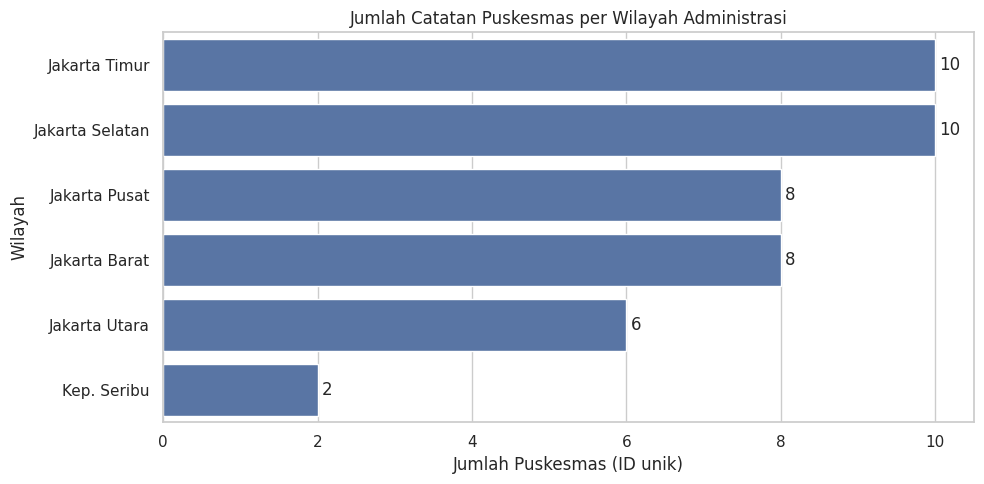

In [7]:
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=distribusi, x="jumlah_puskesmas", y="wilayah_ringkas")
ax.set_title("Jumlah Catatan Puskesmas per Wilayah Administrasi")
ax.set_xlabel("Jumlah Puskesmas (ID unik)")
ax.set_ylabel("Wilayah")
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)
plt.tight_layout()
plt.show()

## 6. Pemeriksaan kualitas data per wilayah

In [8]:
quality_by_region = (
    df.groupby("wilayah_ringkas")
      .agg(
          total=("id_puskesmas", "size"),
          koordinat_valid=("koordinat_valid", "sum"),
          email_format_ok=("email_format_ok", "sum"),
          website_dengan_scheme=("website_has_scheme", "sum")
      )
      .reset_index()
)
quality_by_region["email_format_issue"] = quality_by_region["total"] - quality_by_region["email_format_ok"]
quality_by_region["koordinat_issue"] = quality_by_region["total"] - quality_by_region["koordinat_valid"]
display(quality_by_region.sort_values("total", ascending=False))

,wilayah_ringkas,total,koordinat_valid,email_format_ok,website_dengan_scheme,email_format_issue,koordinat_issue
3,Jakarta Timur,10,10,0,7,10,0
2,Jakarta Selatan,10,10,0,8,10,0
1,Jakarta Pusat,8,8,0,5,8,0
0,Jakarta Barat,8,8,0,4,8,0
4,Jakarta Utara,6,6,0,4,6,0
5,Kep. Seribu,2,2,0,1,2,0


## 7. Analisis kontak: indikasi format, bukan validitas layanan

In [9]:
contact_summary = pd.DataFrame({
    "indikator": [
        "Telepon terisi",
        "Email terisi",
        "Email sesuai pola dasar",
        "Website terisi",
        "Website memakai http/https"
    ],
    "jumlah": [
        df["no_telepon"].notna().sum(),
        df["email"].notna().sum(),
        df["email_format_ok"].sum(),
        df["website_puskesmas"].notna().sum(),
        df["website_has_scheme"].sum()
    ]
})
contact_summary["persentase"] = (contact_summary["jumlah"] / len(df) * 100).round(1)
display(contact_summary)

# Tinjau baris yang perlu pemeriksaan manual
display(df.loc[~df["email_format_ok"], [
    "nama_puskesmas", "wilayah_puskesmas", "email"
]])

,indikator,jumlah,persentase
0,Telepon terisi,44,100.0
1,Email terisi,44,100.0
2,Email sesuai pola dasar,0,0.0
3,Website terisi,44,100.0
4,Website memakai http/https,29,65.9


,nama_puskesmas,wilayah_puskesmas,email
0,PUSKESMAS CEMPAKA PUTIH,KOTA ADM. JAKARTA PUSAT,PUSKESMASKECCEMPUT@JAKARTA.GO.ID
1,PUSKESMAS GAMBIR,KOTA ADM. JAKARTA PUSAT,PUSKESMASGAMBIR@JAKARTA.GO.ID
2,PUSKESMAS JOHAR BARU,KOTA ADM. JAKARTA PUSAT,PUSKESMAS.JOHARBARU@JAKARTA.GO.ID
3,PUSKESMAS KEMAYORAN,KOTA ADM. JAKARTA PUSAT,"PKCKEMAYORAN@GMAIL.COM, PUSKESMASKECKEMAYORAN@..."
4,PUSKESMAS MENTENG,KOTA ADM. JAKARTA PUSAT,PKM_KECMENTENG2YAHOO.CO.ID
5,PUSKESMAS SAWAH BESAR,KOTA ADM. JAKARTA PUSAT,"PUSKESMASKECSAWAHBESAR@JAKARTA.GO.ID, PUSKESMA..."
6,PUSKESMAS SENEN,KOTA ADM. JAKARTA PUSAT,PUSKESMASSENEN@JAKARTA.GO.ID
7,PUSKESMAS TANAH ABANG,KOTA ADM. JAKARTA PUSAT,PUSKESKECTANAHABANG@JAKARTA.GO.ID
8,PUSKESMAS CILINCING,KOTA ADM. JAKARTA UTARA,PUSKESMAS.CILINCING@JAKARTA.GO.ID
9,PUSKESMAS KELAPA GADING,KOTA ADM. JAKARTA UTARA,PUSKESMAS.KELAPAGADING@JAKARTA.GO.ID


## 8. Visualisasi lokasi berdasarkan koordinat

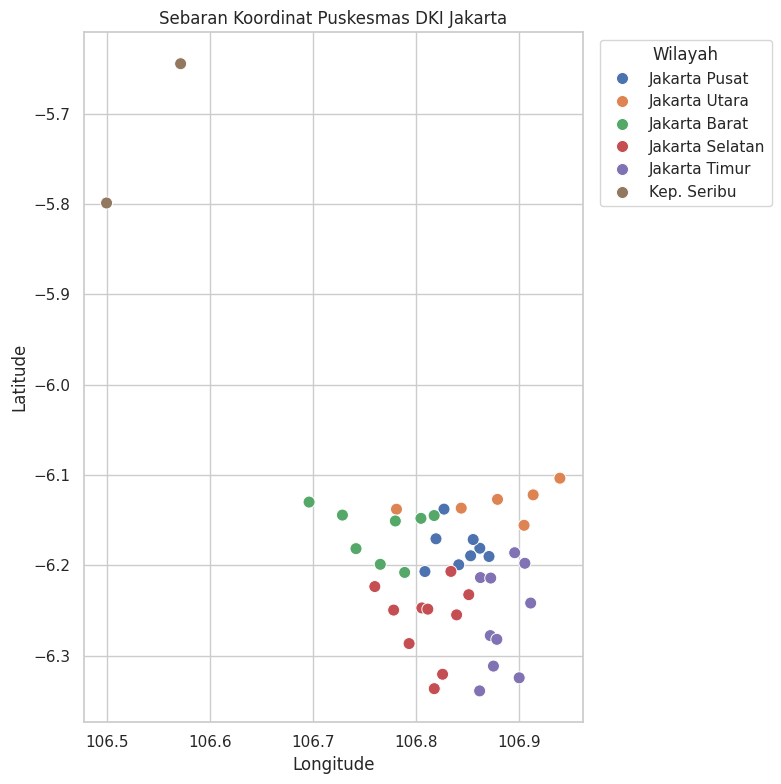

In [10]:
# Scatter plot longitude-latitude; bukan peta jalan atau batas administrasi
plt.figure(figsize=(8, 8))
ax = sns.scatterplot(
    data=df,
    x="longitude_puskesmas",
    y="latitude_puskesmas",
    hue="wilayah_ringkas",
    s=75
)
ax.set_title("Sebaran Koordinat Puskesmas DKI Jakarta")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.legend(title="Wilayah", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 9. Susun temuan otomatis awal

In [13]:
import folium
from folium.plugins import MarkerCluster

# 1. Tentukan titik tengah peta (pusat DKI Jakarta secara umum)
map_center = [df['latitude_puskesmas'].mean(), df['longitude_puskesmas'].mean()]

# 2. Inisiasi peta Folium
m = folium.Map(location=map_center, zoom_start=11, tiles="OpenStreetMap")

# 3. Gunakan MarkerCluster agar titik-titik yang berdekatan mengelompok dengan rapi saat di-zoom out
marker_cluster = MarkerCluster().add_to(m)

# 4. Tambahkan setiap koordinat Puskesmas dari dataset ke dalam peta
for idx, row in df.iterrows():
    # Pastikan koordinat tidak kosong/NaN sebelum di-plot
    if pd.notna(row['latitude_puskesmas']) and pd.notna(row['longitude_puskesmas']):
        popup_text = f"""
        <b>{row['nama_puskesmas']}</b><br>
        Wilayah: {row['wilayah_ringkas']}<br>
        Alamat: {row['alamat_puskesmas']}<br>
        Telepon: {row['no_telepon']}
        """

        folium.Marker(
            location=[row['latitude_puskesmas'], row['longitude_puskesmas']],
            popup=folium.Popup(popup_text, max_width=300),
            tooltip=row['nama_puskesmas'],
            icon=folium.Icon(color="cadetblue", icon="plus-sign", prefix="glyphicon")
        ).add_to(marker_cluster)

# 5. Tampilkan peta interaktif
m

In [ ]:
top_region = distribusi.iloc[0]
bottom_region = distribusi.iloc[-1]
email_issues = int((~df["email_format_ok"]).sum())
coord_issues = int((~df["koordinat_valid"]).sum())

print(f"Jumlah baris: {len(df)}")
print(f"Jumlah ID unik: {df['id_puskesmas'].nunique()}")
print(f"Wilayah dengan catatan terbanyak: {top_region['wilayah_ringkas']} ({top_region['jumlah_puskesmas']})")
print(f"Wilayah dengan catatan paling sedikit: {bottom_region['wilayah_ringkas']} ({bottom_region['jumlah_puskesmas']})")
print(f"Email yang gagal pemeriksaan format dasar: {email_issues}")
print(f"Koordinat di luar rentang pemeriksaan: {coord_issues}")

print("\\nInterpretasi:")
print("- Perbedaan jumlah fasilitas bersifat deskriptif; belum menunjukkan akses yang lebih baik atau buruk.")
print("- Format email yang gagal harus diperiksa manual dan tidak otomatis berarti email tidak aktif.")
print("- Untuk menilai pemerataan, tambahkan jumlah penduduk per wilayah dan samakan tahun serta tingkat geografisnya.")

Jumlah baris: 44
Jumlah ID unik: 44
Wilayah dengan catatan terbanyak: Jakarta Timur (10)
Wilayah dengan catatan paling sedikit: Kep. Seribu (2)
Email yang gagal pemeriksaan format dasar: 44
Koordinat di luar rentang pemeriksaan: 0
\nInterpretasi:
- Perbedaan jumlah fasilitas bersifat deskriptif; belum menunjukkan akses yang lebih baik atau buruk.
- Format email yang gagal harus diperiksa manual dan tidak otomatis berarti email tidak aktif.
- Untuk menilai pemerataan, tambahkan jumlah penduduk per wilayah dan samakan tahun serta tingkat geografisnya.


### Plot Batas Administratif DKI Jakarta Menggunakan GeoJSON (Presisi & Offline-Friendly/Statis)

Menggunakan visualisasi batas wilayah lokal (tanpa koneksi internet):


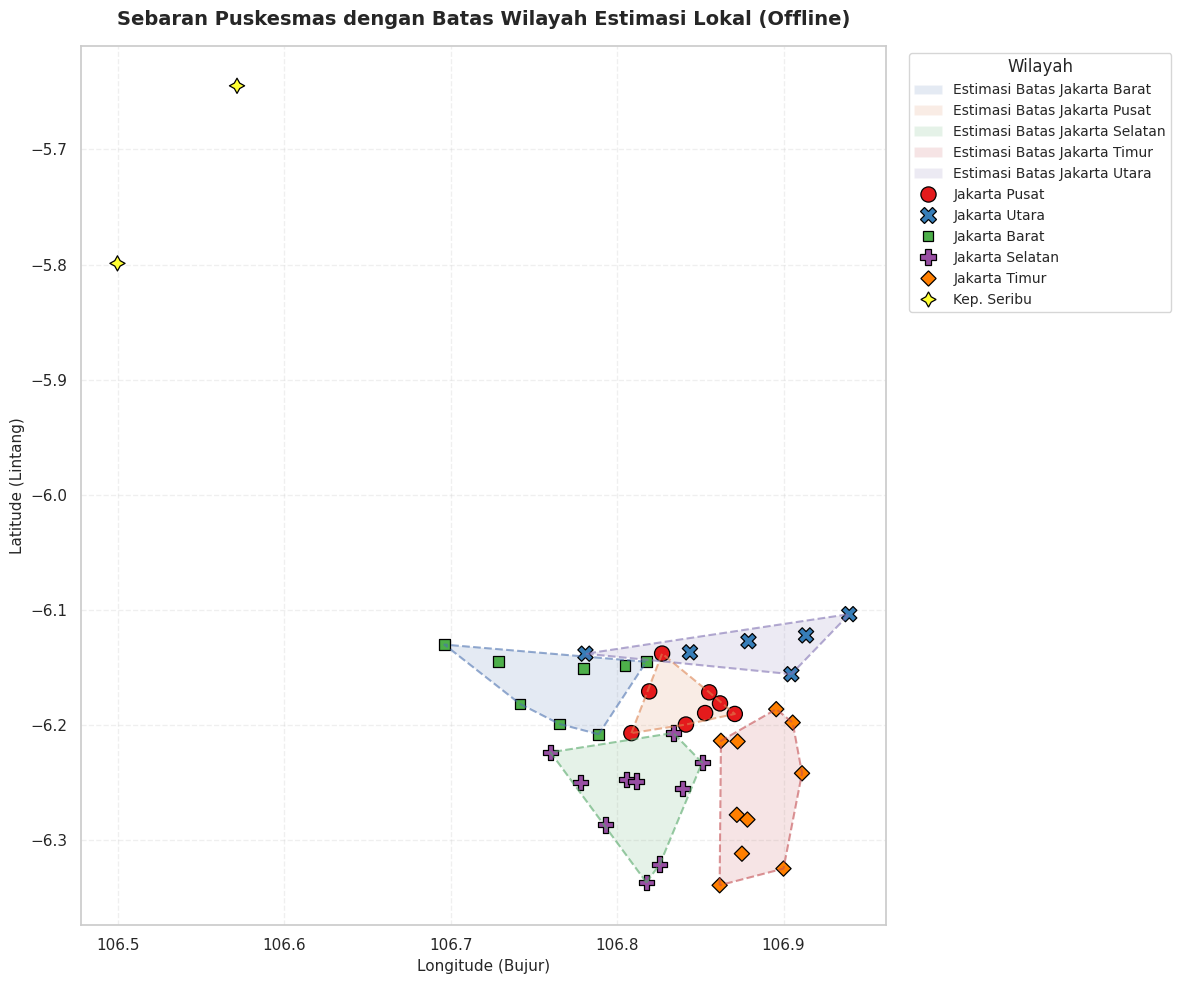

In [19]:
import urllib.request
import json
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.geometry import MultiPoint

# Sumber GeoJSON DKI Jakarta yang sangat stabil dari CDN resmi
geojson_url = "https://cdn.jsdelivr.net/gh/carlesoctav/jakarta-geojson@master/kabupaten-kota.geojson"
geojson_path = "jakarta_kota.geojson"

try:
    # Unduh file batas administratif kota DKI Jakarta
    urllib.request.urlretrieve(geojson_url, geojson_path)
    jakarta_map = gpd.read_file(geojson_path)

    fig, ax = plt.subplots(figsize=(12, 10))

    # Gambar peta batas administratif
    jakarta_map.plot(
        ax=ax,
        color="#f5f6fa",
        edgecolor="#7f8c8d",
        linewidth=1.5,
        alpha=0.9
    )

    # Plot titik koordinat Puskesmas
    sns.scatterplot(
        data=df,
        x="longitude_puskesmas",
        y="latitude_puskesmas",
        hue="wilayah_ringkas",
        style="wilayah_ringkas",
        s=120,
        palette="Set1",
        edgecolor="black",
        linewidth=0.9,
        ax=ax
    )

    # Batasi koordinat agar fokus pas di daratan DKI Jakarta
    plt.xlim(106.65, 106.98)
    plt.ylim(-6.38, -6.08)

    plt.title("Visualisasi Presisi: Sebaran Puskesmas pada Batas Wilayah DKI Jakarta", fontsize=14, pad=15, fontweight='bold')
    plt.xlabel("Longitude (Bujur)", fontsize=11)
    plt.ylabel("Latitude (Lintang)", fontsize=11)
    plt.legend(title="Wilayah Administrasi", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

except Exception as e:
    print("Menggunakan visualisasi batas wilayah lokal (tanpa koneksi internet):")

    fig, ax = plt.subplots(figsize=(12, 10))

    # Membuat area batas wilayah buatan (Convex Hull) berdasarkan sebaran koordinat puskesmas lokal
    for wilayah, group in df.groupby("wilayah_ringkas"):
        if len(group) >= 3:
            points = MultiPoint(list(zip(group['longitude_puskesmas'], group['latitude_puskesmas'])))
            hull = points.convex_hull
            x, y = hull.exterior.xy
            ax.fill(x, y, alpha=0.15, label=f"Estimasi Batas {wilayah}")
            ax.plot(x, y, linestyle="--", linewidth=1.5, alpha=0.6)

    # Plot koordinat titik Puskesmas
    sns.scatterplot(
        data=df,
        x="longitude_puskesmas",
        y="latitude_puskesmas",
        hue="wilayah_ringkas",
        style="wilayah_ringkas",
        s=120,
        palette="Set1",
        edgecolor="black",
        linewidth=0.9,
        ax=ax
    )

    plt.title("Sebaran Puskesmas dengan Batas Wilayah Estimasi Lokal (Offline)", fontsize=14, pad=15, fontweight='bold')
    plt.xlabel("Longitude (Bujur)", fontsize=11)
    plt.ylabel("Latitude (Lintang)", fontsize=11)
    plt.legend(title="Wilayah", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

## 10. Ekspor data bersih dan tabel ringkasan

In [ ]:
df.to_csv("puskesmas_cleaned.csv", index=False)
distribusi.to_csv("puskesmas_distribution_by_region.csv", index=False)
quality_by_region.to_csv("puskesmas_quality_by_region.csv", index=False)

from google.colab import files
files.download("puskesmas_cleaned.csv")
files.download("puskesmas_distribution_by_region.csv")
files.download("puskesmas_quality_by_region.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 11. Keterbatasan dan analisis lanjutan



- Dataset ini merupakan snapshot periode 2025; tidak dapat digunakan untuk tren waktu.
- Jumlah catatan fasilitas bukan ukuran aksesibilitas, kapasitas, mutu, atau utilisasi layanan.
- Scatter plot koordinat menunjukkan posisi relatif, tetapi bukan jarak perjalanan atau jangkauan layanan.
- Untuk analisis penduduk per Puskesmas, gabungkan data penduduk dengan tingkat wilayah dan tahun yang cocok.
- Sebelum mempublikasikan, verifikasi definisi unit fasilitas dan metadata dataset di portal sumber.
- Dokumentasikan sumber, tanggal akses, aturan cleaning, dan semua asumsi di README GitHub.